# Actividad 5 — Marketing bancario y MLOps

## 1. Preparación del entorno

Instalo versiones compatibles de MLflow y PyArrow antes de importarlas. La celda comprueba paquetes ya cargados: si alguno cambia, reinicio la sesión una sola vez y continúo desde esta misma celda. No uso `force-reinstall`, para evitar reemplazar indiscriminadamente NumPy y otras dependencias. La verificación posterior muestra las versiones efectivamente utilizadas.

In [1]:
import sys, subprocess, importlib.metadata
requisitos=['mlflow==2.22.0','pyarrow==19.0.1','sqlalchemy==2.0.43','kagglehub>=0.3,<1','nbformat>=5,<6']
antes={p:(importlib.metadata.version(p) if importlib.util.find_spec(p) else None)
       for p in ['numpy','pandas','sklearn','pyarrow','mlflow','sqlalchemy'] if p!='sklearn'}
cargados={p for p in antes if p in sys.modules}
subprocess.check_call([sys.executable,'-m','pip','install','-q',*requisitos])
despues={p:importlib.metadata.version(p) for p in antes}
if any(antes[p]!=despues[p] for p in cargados):
    raise RuntimeError('Se actualizaron paquetes ya cargados. Reinicia la sesión de Colab y ejecuta desde el inicio.')
import pyarrow, pyarrow.fs, mlflow
print('PyArrow:',pyarrow.__version__,'| MLflow:',mlflow.__version__)


PyArrow: 19.0.1 | MLflow: 2.22.0


In [2]:
from pathlib import Path
import os, sys, json, hashlib, shutil, time, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from scipy.stats import binomtest
try:
    from IPython.display import display, Markdown
except ImportError:
    def display(obj): print(obj)
    def Markdown(text): return text
import joblib
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

# El script define proyecto antes de ejecutar estas instrucciones.
if 'proyecto' not in globals():
    proyecto = Path('/content/Actividad5') if Path('/content').exists() else Path.cwd()/'Actividad5'
proyecto = proyecto.resolve()
for sub in ['datos/datos_ini','datos/datos_limp','fuentes','resultados',
            'evidencias/mlflow','evidencias/comparacion_modelos','modelos']:
    (proyecto/sub).mkdir(parents=True, exist_ok=True)
RESULTADOS = proyecto/'resultados'
GRAFICAS = proyecto/'evidencias/comparacion_modelos'
SEED = 42
print('Directorio del proyecto:', proyecto)
# Guardo y muestro cada figura; el script usa backend Agg.
numero_figura=0
def mostrar_y_guardar():
    global numero_figura
    numero_figura += 1
    fig=plt.gcf()
    fig.savefig(GRAFICAS/f'{numero_figura:02d}_grafica.png',dpi=180,bbox_inches='tight')
    plt.show()
    plt.close(fig)


Directorio del proyecto: /content/Actividad5


## 2. Estructura del proyecto y programas

In [3]:
# Crear el programa de limpieza
# El texto entre comillas se guarda como un archivo Python.
PREP_SOURCE = r'''
"""Limpieza determinista de Bank Marketing; no aprende estadísticas globales."""
import numpy as np
import pandas as pd

def limpiar_datos(datos):
    d=datos.copy()
    d.columns=d.columns.str.strip()
    for c in d.select_dtypes(include=['object','string']).columns:
        d[c]=d[c].str.strip().str.lower().replace('',np.nan)
    numericas=['age','duration','campaign','pdays','previous','emp.var.rate',
               'cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
    for c in numericas:
        d[c]=pd.to_numeric(d[c],errors='raise')
    if d.y.isna().any() or not d.y.isin(['yes','no']).all():
        raise ValueError('Objetivo ausente o inválido')
    if not d.age.dropna().between(1,120).all():
        raise ValueError('Revisar edad fuera del intervalo de control')
    if (d.campaign.dropna()<1).any():
        raise ValueError('campaign debe ser al menos 1')
    for c in ['duration','pdays','previous']:
        if (d[c].dropna()<0).any(): raise ValueError('Valor negativo en '+c)
    d['y']=d.y.map({'no':0,'yes':1}).astype(int)
    d['sin_contacto_previo']=d.pdays.eq(999).astype(int)
    d['pdays']=d.pdays.mask(d.pdays.eq(999),0)
    return d.drop(columns='duration')
'''

(proyecto / 'fuentes/datos_prep.py').write_text(PREP_SOURCE.lstrip('\n'), encoding='utf-8')
print('Archivo creado: fuentes/datos_prep.py')

Archivo creado: fuentes/datos_prep.py


In [4]:
# Crear el programa de entrenamiento y MLflow
# El texto entre comillas se guarda como un archivo Python.
TRAIN_SOURCE = r'''
"""Entrenamiento reproducible y registro MLflow de Actividad5.
Uso: python fuentes/train.py --root .
Prueba funcional (no entregar sus métricas): --smoke
"""
import argparse
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
parser=argparse.ArgumentParser()
parser.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1])
parser.add_argument('--smoke',action='store_true')
args=parser.parse_args()
proyecto=args.root.resolve()
MODO_PRUEBA_RAPIDA=args.smoke
from pathlib import Path
import os, sys, json, hashlib, shutil, time, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from scipy.stats import binomtest
try:
    from IPython.display import display, Markdown
except ImportError:
    def display(obj): print(obj)
    def Markdown(text): return text
import joblib
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

# El script define proyecto antes de ejecutar estas instrucciones.
if 'proyecto' not in globals():
    proyecto = Path('/content/Actividad5') if Path('/content').exists() else Path.cwd()/'Actividad5'
proyecto = proyecto.resolve()
for sub in ['datos/datos_ini','datos/datos_limp','fuentes','resultados',
            'evidencias/mlflow','evidencias/comparacion_modelos','modelos']:
    (proyecto/sub).mkdir(parents=True, exist_ok=True)
RESULTADOS = proyecto/'resultados'
GRAFICAS = proyecto/'evidencias/comparacion_modelos'
SEED = 42
print('Directorio del proyecto:', proyecto)
# Guardo y muestro cada figura; el script usa backend Agg.
numero_figura=0
def mostrar_y_guardar():
    global numero_figura
    numero_figura += 1
    fig=plt.gcf()
    fig.savefig(GRAFICAS/f'{numero_figura:02d}_grafica.png',dpi=180,bbox_inches='tight')
    plt.show()
    plt.close(fig)


import kagglehub
import urllib.request, zipfile, io
archivo=proyecto/'datos/datos_ini/bank-additional-full.csv'
fuente='Archivo original conservado en el proyecto'
if not archivo.exists():
    try:
        path=kagglehub.dataset_download('sahistapatel96/bankadditionalfullcsv')
        candidatos=list(Path(path).rglob('bank-additional-full.csv'))
        if len(candidatos)!=1: raise FileNotFoundError('Versión completa no localizada')
        shutil.copy2(candidatos[0],archivo)
        fuente='Kaggle: sahistapatel96/bankadditionalfullcsv'
    except Exception as error:
        print('Kaggle no disponible; uso la fuente original UCI:',type(error).__name__)
        with urllib.request.urlopen('https://archive.ics.uci.edu/static/public/222/bank+marketing.zip',timeout=90) as r:
            z=zipfile.ZipFile(io.BytesIO(r.read()))
        directos=[x for x in z.namelist() if x.endswith('bank-additional-full.csv')]
        if directos:
            contenido=z.read(directos[0])
        else:
            interno=next(x for x in z.namelist() if x.endswith('bank-additional.zip'))
            zi=zipfile.ZipFile(io.BytesIO(z.read(interno)))
            contenido=zi.read(next(x for x in zi.namelist() if x.endswith('bank-additional-full.csv')))
        archivo.write_bytes(contenido)
        fuente='UCI original (respaldo de descarga)'
df=pd.read_csv(archivo,sep=';')
assert df.shape==(41188,21), f'Dataset inesperado: {df.shape}'
sha=hashlib.sha256(archivo.read_bytes()).hexdigest()
manifest={'sha256_original':sha,'fuente_efectiva':fuente,'filas':len(df),'columnas':len(df.columns)}
(RESULTADOS/'manifest_datos.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('Datos:',df.shape,'| SHA256:',sha)
display(df.head())


diccionario=pd.DataFrame([('age', 'Numérica', 'Edad en años'), ('job', 'Categórica', 'Ocupación'), ('marital', 'Categórica', 'Estado civil; divorced incluye viudez'), ('education', 'Categórica', 'Nivel educativo'), ('default', 'Categórica', 'Crédito en impago'), ('housing', 'Categórica', 'Préstamo hipotecario'), ('loan', 'Categórica', 'Préstamo personal'), ('contact', 'Categórica', 'Canal del contacto'), ('month', 'Categórica', 'Mes del contacto'), ('day_of_week', 'Categórica', 'Día del contacto'), ('duration', 'Numérica excluida', 'Duración de llamada en segundos'), ('campaign', 'Numérica', 'Contactos actuales; incluye el contacto actual'), ('pdays', 'Numérica', 'Días desde campaña previa; 999 indica sin contacto'), ('previous', 'Numérica', 'Contactos anteriores a la campaña actual'), ('poutcome', 'Categórica', 'Resultado de campaña previa'), ('emp.var.rate', 'Numérica', 'Variación trimestral de empleo'), ('cons.price.idx', 'Numérica', 'Índice mensual de precios'), ('cons.conf.idx', 'Numérica', 'Confianza mensual del consumidor'), ('euribor3m', 'Numérica', 'Euríbor a tres meses, diario'), ('nr.employed', 'Numérica', 'Indicador trimestral de número de empleados'), ('y', 'Objetivo', 'Contrató: yes=1, no=0')],columns=['variable','tipo','descripcion'])
diccionario.to_csv(RESULTADOS/'diccionario_datos.csv',index=False)
display(diccionario)


# Reviso la calidad de los datos del DataFrame.
diagnostico = pd.DataFrame({
    "tipo_original": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "desconocidos": df.apply(
        lambda columna: columna.eq("unknown").sum()
    ),
    "valores_unicos": df.nunique()
})

display(diagnostico)

print("Registros:", len(df))
print("Filas idénticas:", df.duplicated().sum())
diagnostico.to_csv(RESULTADOS/'diagnostico_original.csv')
sys.path.insert(0,str(proyecto/'fuentes'))
from datos_prep import limpiar_datos
df_limpio=limpiar_datos(df)
df_limpio.to_csv(proyecto/'datos/datos_limp/bank_limpio.csv',index=False)
print('Datos limpios:',df_limpio.shape)
print('Filas idénticas conservadas:',df.duplicated().sum())


# CONFIGURACIÓN Y DATOS

AZUL_OSCURO = "#123B63"
AZUL_MEDIO = "#347FC4"
AZUL_CLARO = "#A9CDEB"
AZUL_SUAVE = "#EAF2FA"

sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#D5DFE8",
        "axes.labelcolor": "#334155",
        "text.color": AZUL_OSCURO,
        "xtick.color": "#475569",
        "ytick.color": "#475569",
        "font.size": 11,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "figure.dpi": 120
    }
)

# La prueba rápida usa una muestra y no sirve como resultado final.
if globals().get('MODO_PRUEBA_RAPIDA',False):
    df_limpio=df_limpio.sample(n=800,random_state=SEED).sort_index()
# Conservo el orden original y reservo el último 20% para prueba.
corte = int(len(df_limpio) * 0.80)

entrenamiento = df_limpio.iloc[:corte].copy()
prueba = df_limpio.iloc[corte:].copy()

X_train = entrenamiento.drop(columns="y")
y_train = entrenamiento["y"]

X_test = prueba.drop(columns="y")
y_test = prueba["y"]

assert set(entrenamiento["y"].unique()) == {0, 1}, (
    "La variable y debe estar codificada como 0 y 1."
)

print(f"Entrenamiento: {len(entrenamiento):,} registros")
print(f"Prueba reservada: {len(prueba):,} registros")


def estilo_limpio(ax, eje="y"):
    """Agrego una cuadrícula tenue sobre el eje indicado."""
    ax.set_axisbelow(True)
    ax.grid(axis=eje, color="#E8EEF4", linewidth=0.7)
    ax.tick_params(length=0)


# DISTRIBUCIÓN DE LA CONTRATACIÓN

conteos = (
    entrenamiento["y"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

porcentajes = conteos / conteos.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))

barras = ax.bar(
    ["No contrató", "Sí contrató"],
    conteos.values,
    color=[AZUL_CLARO, AZUL_OSCURO],
    width=0.55
)

for barra, porcentaje in zip(barras, porcentajes):
    ax.annotate(
        f"{int(barra.get_height()):,}  ·  {porcentaje:.1f}%",
        xy=(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height()
        ),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title("Distribución de la contratación", loc="left", pad=20)
ax.set_ylabel("Observaciones")
ax.set_ylim(0, conteos.max() * 1.18)

estilo_limpio(ax)
plt.tight_layout()
mostrar_y_guardar()


# CONTRATACIÓN POR OCUPACIÓN

etiquetas_ocupacion = {
    "admin.": "Administración",
    "blue-collar": "Trabajo manual",
    "entrepreneur": "Emprendimiento",
    "housemaid": "Trabajo doméstico",
    "management": "Gerencia",
    "retired": "Jubilación",
    "self-employed": "Trabajo independiente",
    "services": "Servicios",
    "student": "Estudiante",
    "technician": "Personal técnico",
    "unemployed": "Desempleo",
    "unknown": "Desconocida"
}

por_ocupacion = (
    entrenamiento.groupby("job")["y"]
    .agg(tasa="mean", registros="size")
    .sort_values("tasa")
)

etiquetas = [
    etiquetas_ocupacion.get(ocupacion, ocupacion)
    for ocupacion in por_ocupacion.index
]

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    etiquetas,
    por_ocupacion["tasa"],
    color=AZUL_MEDIO,
    height=0.65
)

for barra, (_, fila) in zip(barras, por_ocupacion.iterrows()):
    ax.annotate(
        f'{fila["tasa"]:.1%}  ·  n={int(fila["registros"]):,}',
        xy=(
            barra.get_width(),
            barra.get_y() + barra.get_height() / 2
        ),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Tasa de contratación por ocupación",
    loc="left",
    pad=20
)
ax.set_xlabel("Porcentaje de contratación")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, max(por_ocupacion["tasa"].max() * 1.55, 0.10))

estilo_limpio(ax, eje="x")
plt.tight_layout()
mostrar_y_guardar()



# DISTRIBUCIÓN DE EDAD

fig, ax = plt.subplots(figsize=(9, 4.5))

sns.histplot(
    data=entrenamiento,
    x="age",
    bins=25,
    color=AZUL_MEDIO,
    edgecolor="white",
    alpha=0.9,
    ax=ax
)

mediana_edad = entrenamiento["age"].median()

ax.axvline(
    mediana_edad,
    color=AZUL_OSCURO,
    linestyle="--",
    linewidth=1.8,
    label=f"Mediana: {mediana_edad:.0f} años"
)

ax.set_title("Distribución de edad", loc="left", pad=20)
ax.set_xlabel("Edad en años")
ax.set_ylabel("Observaciones")
ax.legend(frameon=False)

estilo_limpio(ax)
plt.tight_layout()
mostrar_y_guardar()



# VALORES EXTREMOS


fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

variables = [
    ("age", "Edad", "Años"),
    ("campaign", "Contactos de campaña actual", "Contactos"),
    ("previous", "Contactos de campañas anteriores", "Contactos")
]

for ax, (columna, titulo, etiqueta) in zip(axes, variables):
    sns.boxplot(
        data=entrenamiento,
        y=columna,
        color=AZUL_CLARO,
        width=0.4,
        linewidth=1.2,
        flierprops={
            "marker": "o",
            "markersize": 3,
            "markerfacecolor": AZUL_MEDIO,
            "markeredgecolor": AZUL_MEDIO,
            "alpha": 0.35
        },
        medianprops={
            "color": AZUL_OSCURO,
            "linewidth": 2
        },
        ax=ax
    )

    ax.set_title(titulo, fontsize=12, pad=15)
    ax.set_ylabel(etiqueta)
    ax.set_xlabel("")
    estilo_limpio(ax)

fig.suptitle(
    "Revisión de valores extremos",
    fontsize=15,
    fontweight="bold",
    x=0.02,
    ha="left"
)

plt.tight_layout(rect=[0, 0, 1, 0.92])
mostrar_y_guardar()

print(
    "Los puntos fuera de los bigotes son candidatos a revisión; "
    "no se eliminan automáticamente."
)


# INFORMACIÓN DESCONOCIDA

categoricas = entrenamiento.select_dtypes(
    include=["object", "string"]
).columns

desconocidos = (
    entrenamiento[categoricas]
    .eq("unknown")
    .mean()
    .sort_values()
)

desconocidos = desconocidos[desconocidos > 0]

if not desconocidos.empty:
    fig, ax = plt.subplots(figsize=(9, 4.5))

    barras = ax.barh(
        desconocidos.index,
        desconocidos.values,
        color=AZUL_MEDIO,
        height=0.6
    )

    for barra, porcentaje in zip(barras, desconocidos.values):
        ax.annotate(
            f"{porcentaje:.1%}",
            xy=(
                barra.get_width(),
                barra.get_y() + barra.get_height() / 2
            ),
            xytext=(7, 0),
            textcoords="offset points",
            va="center"
        )

    ax.set_title("Información desconocida por variable", loc="left", pad=20)
    ax.set_xlabel("Registros con categoría unknown")
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlim(0, desconocidos.max() * 1.25)

    estilo_limpio(ax, eje="x")
    plt.tight_layout()
    mostrar_y_guardar()
else:
    print("No se encontraron categorías unknown en entrenamiento.")



# CORRELACIONES NUMÉRICAS


correlaciones = (
    entrenamiento
    .select_dtypes(include="number")
    .corr()
)

mascara = np.triu(
    np.ones_like(correlaciones, dtype=bool),
    k=1
)

mapa_azules = LinearSegmentedColormap.from_list(
    "escala_azul",
    [AZUL_SUAVE, AZUL_CLARO, AZUL_OSCURO]
)

fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    correlaciones,
    mask=mascara,
    cmap=mapa_azules,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 9},
    linewidths=0.7,
    linecolor="white",
    square=True,
    cbar_kws={
        "label": "Correlación: −1 a +1",
        "shrink": 0.75
    },
    ax=ax
)

ax.set_title(
    "Correlaciones entre variables numéricas",
    loc="left",
    pad=20
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
mostrar_y_guardar()

print(
    "En la matriz, los tonos claros representan correlaciones negativas "
    "y los oscuros positivas. Los números indican su magnitud."
)
pd.DataFrame({'fila_original':df_limpio.index,'particion':
    ['entrenamiento']*corte+['prueba']*(len(df_limpio)-corte)}).to_csv(RESULTADOS/'particiones.csv',index=False)
assert y_train.nunique()==y_test.nunique()==2


# Identifico los tipos de variables únicamente en entrenamiento.
columnas_numericas = X_train.select_dtypes(
    include="number"
).columns.tolist()

columnas_categoricas = X_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()


def crear_preprocesador(escalar=False):
    # Preparo las variables numéricas.
    pasos_numericos = [
        ("imputacion", SimpleImputer(strategy="median"))
    ]

    if escalar:
        pasos_numericos.append(
            ("escalado", StandardScaler())
        )

    # Preparo las variables categóricas.
    pasos_categoricos = [
        (
            "imputacion",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "codificacion",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]

    return ColumnTransformer([
        (
            "numericas",
            Pipeline(pasos_numericos),
            columnas_numericas
        ),
        (
            "categoricas",
            Pipeline(pasos_categoricos),
            columnas_categoricas
        )
    ])


# Modelo 1: regresión logística con escalado numérico.
modelo_logistico = Pipeline([
    ("preprocesamiento", crear_preprocesador(escalar=True)),
    (
        "modelo",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

# Modelo 2: Random Forest sin escalado numérico.
modelo_random_forest = Pipeline([
    ("preprocesamiento", crear_preprocesador(escalar=False)),
    (
        "modelo",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        )
    )
])

# Conservo los modelos para el ajuste posterior.
modelos = {
    "Regresion_logistica": modelo_logistico,
    "Random_Forest": modelo_random_forest
}

for nombre, pipeline in modelos.items():
    print(f"\n{nombre}")
    display(pipeline)

# Defino las configuraciones que voy a comparar.
hiperparametros = {
    "Regresion_logistica": {
        "modelo__C": [0.1, 1.0, 10.0],
        "modelo__class_weight": [None, "balanced"]
    },

    "Random_Forest": {
        "modelo__n_estimators": [100, 200],
        "modelo__max_depth": [8, None],
        "modelo__min_samples_leaf": [2, 10],
        "modelo__class_weight": [None, "balanced"]
    }
}

# Creo los mismos cinco folds para ambos modelos.
validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(validacion.split(X_train, y_train))

# Registro varias métricas y selecciono por F1.
metricas_validacion = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


if globals().get('MODO_PRUEBA_RAPIDA',False):
    hiperparametros={
        'Regresion_logistica':{'modelo__C':[1.0]},
        'Random_Forest':{'modelo__n_estimators':[5],'modelo__max_depth':[3]}}
    folds=list(StratifiedKFold(n_splits=2,shuffle=True,random_state=SEED).split(X_train,y_train))

mlflow.set_tracking_uri('sqlite:///'+str(proyecto/'mlflow.db'))
cliente_mlflow=mlflow.tracking.MlflowClient()
nombre_experimento=('Actividad5_PRUEBA_RAPIDA' if globals().get('MODO_PRUEBA_RAPIDA',False)
                    else 'Actividad5_Marketing_Bancario')
experimento=cliente_mlflow.get_experiment_by_name(nombre_experimento)
id_experimento=(experimento.experiment_id if experimento else
    cliente_mlflow.create_experiment(nombre_experimento,artifact_location=(proyecto/'mlartifacts').as_uri()))
mlflow.set_experiment(experiment_id=id_experimento)

# Conservo versiones, datos y partición para trazabilidad.
paquetes=['numpy','pandas','scikit-learn','scipy','matplotlib','seaborn','mlflow','pyarrow','kagglehub','joblib','sqlalchemy']
versiones={p:importlib.metadata.version(p) for p in paquetes}
(RESULTADOS/'entorno.json').write_text(json.dumps({'python':sys.version,'paquetes':versiones},indent=2))
(proyecto/'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versiones.items())+'\n')


busquedas={}; mejores_modelos={}; resumen=[]; ids_ejecuciones={}
# El checkpoint evita repetir una búsqueda completada si ejecuto la celda otra vez.
# Solo cargo checkpoints creados por este proyecto; joblib no es seguro con archivos ajenos.
for nombre,pipeline in modelos.items():
    firma=hashlib.sha256(json.dumps({'sha':sha,'version_codigo':'1.1.0',
        'params':hiperparametros[nombre],'versiones':versiones,
        'n_train':len(X_train),'indice_train':X_train.index.tolist(),
        'folds':len(folds),'seed':SEED},sort_keys=True).encode()).hexdigest()
    checkpoint=proyecto/'modelos'/f'{nombre}_{firma[:12]}.joblib'
    with mlflow.start_run(run_name=nombre) as run:
        ids_ejecuciones[nombre]=run.info.run_id
        mlflow.set_tags({'version_codigo':'1.1.0','sha256_original':sha,
                        'modo':'prueba_rapida' if globals().get('MODO_PRUEBA_RAPIDA',False) else 'completo'})
        mlflow.log_params({'seed':SEED,'folds':len(folds),'umbral':0.5,'seleccion':'f1',
            'particion':'80_20_orden_original','n_train':len(X_train),'n_test':len(X_test),
            'duration_excluida':True})
        if checkpoint.exists():
            busqueda=joblib.load(checkpoint)
            mlflow.set_tag('origen_ajuste','checkpoint_compatible')
            print('Recuperado:',nombre)
        else:
            print('Ajustando:',nombre,flush=True)
            busqueda=GridSearchCV(pipeline,hiperparametros[nombre],scoring=metricas_validacion,
                refit='f1',cv=folds,n_jobs=2,verbose=1,error_score='raise')
            inicio=time.perf_counter()
            busqueda.fit(X_train,y_train)
            mlflow.log_metric('segundos_ajuste',time.perf_counter()-inicio)
            mlflow.set_tag('origen_ajuste','entrenamiento_nuevo')
            joblib.dump(busqueda,checkpoint)
        busquedas[nombre]=busqueda
        mejores_modelos[nombre]=busqueda.best_estimator_
        indice=busqueda.best_index_
        fila={'modelo':nombre,'mejores_parametros':busqueda.best_params_}
        for m in metricas_validacion:
            valor=float(busqueda.cv_results_[f'mean_test_{m}'][indice])
            fila[f'cv_{m}']=valor
            mlflow.log_metric(f'cv_{m}',valor)
        fila['cv_f1_std']=float(busqueda.cv_results_['std_test_f1'][indice])
        mlflow.log_metric('cv_f1_std',fila['cv_f1_std'])
        resumen.append(fila)
        mlflow.log_params({k:str(v) for k,v in busqueda.best_params_.items()})
        tabla_cv=pd.DataFrame(busqueda.cv_results_)
        ruta_cv=RESULTADOS/f'gridsearch_{nombre}.csv'
        tabla_cv.to_csv(ruta_cv,index=False)
        mlflow.log_artifact(str(ruta_cv),'validacion')
        # Cada configuración aparece como ejecución hija en el panel.
        for i,row in tabla_cv.iterrows():
            with mlflow.start_run(run_name=f'config_{i:02d}',nested=True):
                mlflow.log_params({k:str(v) for k,v in row['params'].items()})
                mlflow.log_metrics({f'cv_{m}':float(row[f'mean_test_{m}']) for m in metricas_validacion})
        ejemplo=X_train.head(5)
        mlflow.sklearn.log_model(busqueda.best_estimator_,artifact_path='modelo',
            signature=infer_signature(ejemplo,busqueda.predict(ejemplo)),input_example=ejemplo)
        mlflow.log_artifact(str(RESULTADOS/'manifest_datos.json'),'datos')
        mlflow.log_artifact(str(RESULTADOS/'entorno.json'),'entorno')
resumen_ajuste=pd.DataFrame(resumen).set_index('modelo').sort_values('cv_f1',ascending=False)
modelo_seleccionado=resumen_ajuste.index[0]
resumen_ajuste.to_csv(RESULTADOS/'metricas_validacion.csv')
display(resumen_ajuste.drop(columns='mejores_parametros').round(4))
print('Seleccionado únicamente por validación:',modelo_seleccionado)



nombres = ["Regresion_logistica", "Random_Forest"]

if "mejores_modelos" not in globals():
    raise RuntimeError("Primero ejecuta el ajuste de hiperparámetros.")

for nombre in nombres:
    if nombre not in mejores_modelos:
        raise RuntimeError(f"Falta terminar el ajuste de {nombre}.")

predicciones = {}
filas_metricas = []

for nombre in nombres:
    modelo = mejores_modelos[nombre]

    # Obtengo la probabilidad de contratación.
    indice_positivo = list(modelo.classes_).index(1)
    probabilidades = modelo.predict_proba(X_test)[:, indice_positivo]

    # Mantengo el mismo umbral para ambos modelos.
    prediccion = (probabilidades >= 0.5).astype(int)
    predicciones[nombre] = prediccion

    filas_metricas.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, prediccion),
        "precision": precision_score(
            y_test, prediccion, zero_division=0
        ),
        "recall": recall_score(
            y_test, prediccion, zero_division=0
        ),
        "f1": f1_score(
            y_test, prediccion, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, probabilidades)
    })

tabla_metricas = (
    pd.DataFrame(filas_metricas)
    .set_index("modelo")
)

print("MÉTRICAS DE LOS MODELOS OPTIMIZADOS EN PRUEBA")
display(tabla_metricas.round(4))

print(
    "La clase positiva es contratación (y=1). "
    "MAE, RMSE y R² no aplican porque es clasificación."
)

# Gráfica comparativa en tonos azules.
fig, ax = plt.subplots(figsize=(11, 5))

tabla_metricas.T.plot.bar(
    ax=ax,
    color=["#123B63", "#79AFE0"],
    rot=0,
    width=0.7
)

ax.set_title("Desempeño de los modelos optimizados", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0, 1.15)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E8EEF4")
ax.set_axisbelow(True)
ax.legend(frameon=False)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", padding=3, fontsize=8)

plt.tight_layout()
mostrar_y_guardar()

# COMPARACIÓN ESTADÍSTICA DE RESULTADOS

y_real = np.asarray(y_test)
pred_lr = predicciones["Regresion_logistica"]
pred_rf = predicciones["Random_Forest"]

# Bootstrap estratificado pareado:
# remuestreo las mismas observaciones para ambos modelos,
# conservando el número de casos de cada clase.
rng = np.random.default_rng(42)

grupos = [
    np.flatnonzero(y_real == clase)
    for clase in [0, 1]
]

diferencias = []

for _ in range(1000):
    indices = np.concatenate([
        rng.choice(grupo, size=len(grupo), replace=True)
        for grupo in grupos
    ])

    diferencias.append(
        f1_score(
            y_real[indices], pred_rf[indices], zero_division=0
        )
        - f1_score(
            y_real[indices], pred_lr[indices], zero_division=0
        )
    )

limite_inferior, limite_superior = np.quantile(
    diferencias, [0.025, 0.975]
)

diferencia_f1 = (
    tabla_metricas.loc["Random_Forest", "f1"]
    - tabla_metricas.loc["Regresion_logistica", "f1"]
)

# McNemar exacto: comparo los errores discordantes.
solo_lr_acierta = int(
    ((pred_lr == y_real) & (pred_rf != y_real)).sum()
)

solo_rf_acierta = int(
    ((pred_lr != y_real) & (pred_rf == y_real)).sum()
)

discordantes = solo_lr_acierta + solo_rf_acierta

p_valor = (
    binomtest(
        solo_lr_acierta,
        n=discordantes,
        p=0.5,
        alternative="two-sided"
    ).pvalue
    if discordantes > 0
    else 1.0
)

comparacion_estadistica = pd.DataFrame({
    "resultado": {
        "Diferencia F1 (RF − logística)": diferencia_f1,
        "IC 95%: límite inferior": limite_inferior,
        "IC 95%: límite superior": limite_superior,
        "Solo logística acierta": solo_lr_acierta,
        "Solo Random Forest acierta": solo_rf_acierta,
        "McNemar: p-valor": p_valor
    }
})

print("\nCOMPARACIÓN ESTADÍSTICA")
display(comparacion_estadistica)

if limite_inferior > 0:
    print("F1: el intervalo favorece a Random Forest.")
elif limite_superior < 0:
    print("F1: el intervalo favorece a regresión logística.")
else:
    print(
        "F1: el intervalo incluye cero; no encuentro evidencia "
        "concluyente de una diferencia. Esto no demuestra equivalencia."
    )

if p_valor < 0.05:
    print(
        "McNemar: detecto diferencias en las tasas de error "
        "al nivel de significancia de 0.05."
    )
else:
    print(
        "McNemar: no detecto diferencias en las tasas de error "
        "al nivel de significancia de 0.05."
    )

# Visualizo la incertidumbre de la diferencia de F1.
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(
    diferencias,
    bins=35,
    color="#79AFE0",
    edgecolor="white"
)

ax.axvline(
    0, color="#64748B", linestyle="--", label="Sin diferencia"
)
ax.axvline(
    limite_inferior, color="#123B63", label="Límites del IC 95%"
)
ax.axvline(limite_superior, color="#123B63")

ax.set_title("Bootstrap pareado: diferencia de F1", loc="left")
ax.set_xlabel("F1 Random Forest − F1 regresión logística")
ax.set_ylabel("Remuestreos")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
mostrar_y_guardar()
tabla_metricas.to_csv(RESULTADOS/'metricas_prueba.csv')
comparacion_estadistica.to_csv(RESULTADOS/'comparacion_estadistica.csv')
print('La inferencia supone filas independientes y no incorpora incertidumbre del entrenamiento.')
print('McNemar compara errores, no F1. No reajusto el modelo usando prueba.')


# Completo las ejecuciones principales con métricas de prueba y artefactos.
for nombre in nombres:
    with mlflow.start_run(run_id=ids_ejecuciones[nombre]):
        mlflow.log_metrics({'test_'+m:float(tabla_metricas.loc[nombre,m]) for m in tabla_metricas.columns})
        mlflow.set_tag('seleccionado_por_validacion',str(nombre==modelo_seleccionado))
        mlflow.log_artifacts(str(GRAFICAS),'graficas')
        for p in ['metricas_prueba.csv','comparacion_estadistica.csv','metricas_validacion.csv','diccionario_datos.csv']:
            mlflow.log_artifact(str(RESULTADOS/p),'resultados')
        mlflow.log_artifacts(str(proyecto/'fuentes'),'codigo')
# Verifico parámetros, métricas, artefactos y carga del modelo registrado.
filas=[]
for nombre,rid in ids_ejecuciones.items():
    r=cliente_mlflow.get_run(rid)
    assert r.info.status=='FINISHED' and r.data.params and 'test_f1' in r.data.metrics
    assert cliente_mlflow.list_artifacts(rid,'modelo')
    recuperado=mlflow.sklearn.load_model(f'runs:/{rid}/modelo')
    np.testing.assert_array_equal(recuperado.predict(X_test.head(5)),mejores_modelos[nombre].predict(X_test.head(5)))
    filas.append({'modelo':nombre,'run_id':rid,'estado':r.info.status,**r.data.metrics})
evidencia=pd.DataFrame(filas)
display(evidencia)
evidencia.to_csv(proyecto/'evidencias/mlflow/ejecuciones_verificadas.csv',index=False)
cliente_mlflow.search_runs([id_experimento])
(RESULTADOS/'run_ids.json').write_text(json.dumps(ids_ejecuciones,indent=2))
print('MLflow verificado: parámetros, métricas, artefactos y predicción del modelo recuperado.')
'''

(proyecto / 'fuentes/train.py').write_text(TRAIN_SOURCE.lstrip('\n'), encoding='utf-8')
print('Archivo creado: fuentes/train.py')

Archivo creado: fuentes/train.py


## 3. Descripción del dataset, fuente y supuestos

Utilizo **Bank Marketing**, versión `bank-additional-full.csv` (41,188 observaciones y 20 predictores originales más `y`). Son campañas telefónicas de una institución bancaria portuguesa entre mayo de 2008 y noviembre de 2010, ordenadas por fecha.

- Kaggle: https://www.kaggle.com/datasets/sahistapatel96/bankadditionalfullcsv
- Fuente original: https://archive.ics.uci.edu/dataset/222/bank+marketing
- DOI: https://doi.org/10.24432/C5K306
- Moro, S., Cortez, P. y Rita, P. (2014). *A Data-Driven Approach to Predict the Success of Bank Telemarketing*. Decision Support Systems, 62, 22–31. Licencia de UCI: CC BY 4.0.

**Supuestos:** predigo antes de una llamada y excluyo `duration`. Supongo disponibles el canal, calendario, número de contacto e indicadores económicos en ese momento. Para seleccionar clientes desde el inicio de toda una campaña tendría que revisar esas variables. No hay ID de cliente ni fecha exacta; no puedo descartar dependencia entre filas. No interpreto asociaciones como causalidad ni generalizo directamente a banca mexicana actual.

In [5]:
import kagglehub
import urllib.request, zipfile, io
archivo=proyecto/'datos/datos_ini/bank-additional-full.csv'
fuente='Archivo original conservado en el proyecto'
if not archivo.exists():
    try:
        path=kagglehub.dataset_download('sahistapatel96/bankadditionalfullcsv')
        candidatos=list(Path(path).rglob('bank-additional-full.csv'))
        if len(candidatos)!=1: raise FileNotFoundError('Versión completa no localizada')
        shutil.copy2(candidatos[0],archivo)
        fuente='Kaggle: sahistapatel96/bankadditionalfullcsv'
    except Exception as error:
        print('Kaggle no disponible; uso la fuente original UCI:',type(error).__name__)
        with urllib.request.urlopen('https://archive.ics.uci.edu/static/public/222/bank+marketing.zip',timeout=90) as r:
            z=zipfile.ZipFile(io.BytesIO(r.read()))
        directos=[x for x in z.namelist() if x.endswith('bank-additional-full.csv')]
        if directos:
            contenido=z.read(directos[0])
        else:
            interno=next(x for x in z.namelist() if x.endswith('bank-additional.zip'))
            zi=zipfile.ZipFile(io.BytesIO(z.read(interno)))
            contenido=zi.read(next(x for x in zi.namelist() if x.endswith('bank-additional-full.csv')))
        archivo.write_bytes(contenido)
        fuente='UCI original (respaldo de descarga)'
df=pd.read_csv(archivo,sep=';')
assert df.shape==(41188,21), f'Dataset inesperado: {df.shape}'
sha=hashlib.sha256(archivo.read_bytes()).hexdigest()
manifest={'sha256_original':sha,'fuente_efectiva':fuente,'filas':len(df),'columnas':len(df.columns)}
(RESULTADOS/'manifest_datos.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('Datos:',df.shape,'| SHA256:',sha)
display(df.head())


Datos: (41188, 21) | SHA256: 233e260d5d1d506a2c10381da5b8c2f75f2c08d1b373ca7b825e39ebe1bd30df


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [6]:
diccionario=pd.DataFrame([('age', 'Numérica', 'Edad en años'), ('job', 'Categórica', 'Ocupación'), ('marital', 'Categórica', 'Estado civil; divorced incluye viudez'), ('education', 'Categórica', 'Nivel educativo'), ('default', 'Categórica', 'Crédito en impago'), ('housing', 'Categórica', 'Préstamo hipotecario'), ('loan', 'Categórica', 'Préstamo personal'), ('contact', 'Categórica', 'Canal del contacto'), ('month', 'Categórica', 'Mes del contacto'), ('day_of_week', 'Categórica', 'Día del contacto'), ('duration', 'Numérica excluida', 'Duración de llamada en segundos'), ('campaign', 'Numérica', 'Contactos actuales; incluye el contacto actual'), ('pdays', 'Numérica', 'Días desde campaña previa; 999 indica sin contacto'), ('previous', 'Numérica', 'Contactos anteriores a la campaña actual'), ('poutcome', 'Categórica', 'Resultado de campaña previa'), ('emp.var.rate', 'Numérica', 'Variación trimestral de empleo'), ('cons.price.idx', 'Numérica', 'Índice mensual de precios'), ('cons.conf.idx', 'Numérica', 'Confianza mensual del consumidor'), ('euribor3m', 'Numérica', 'Euríbor a tres meses, diario'), ('nr.employed', 'Numérica', 'Indicador trimestral de número de empleados'), ('y', 'Objetivo', 'Contrató: yes=1, no=0')],columns=['variable','tipo','descripcion'])
diccionario.to_csv(RESULTADOS/'diccionario_datos.csv',index=False)
display(diccionario)


,variable,tipo,descripcion
0,age,Numérica,Edad en años
1,job,Categórica,Ocupación
2,marital,Categórica,Estado civil; divorced incluye viudez
3,education,Categórica,Nivel educativo
4,default,Categórica,Crédito en impago
5,housing,Categórica,Préstamo hipotecario
6,loan,Categórica,Préstamo personal
7,contact,Categórica,Canal del contacto
8,month,Categórica,Mes del contacto
9,day_of_week,Categórica,Día del contacto


## 4. Limpieza y estandarización

Normalizo textos y tipos, convierto blancos a nulos y conservo `unknown` como categoría explícita. No elimino filas idénticas sin ID verificable. Transformo `pdays=999` en cero junto con una bandera de ausencia de contacto previo; esto evita interpretar 999 como días reales. Verifico rangos básicos sin eliminar extremos por una regla estadística.

La imputación y One-Hot se aprenden dentro de cada fold; en regresión logística también ajusto StandardScaler. Random Forest no requiere escalado. El CSV limpio conserva nulos si existen, ya que su imputación forma parte del modelo.

In [7]:
# Reviso la calidad de los datos del DataFrame.
diagnostico = pd.DataFrame({
    "tipo_original": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "desconocidos": df.apply(
        lambda columna: columna.eq("unknown").sum()
    ),
    "valores_unicos": df.nunique()
})

display(diagnostico)

print("Registros:", len(df))
print("Filas idénticas:", df.duplicated().sum())
diagnostico.to_csv(RESULTADOS/'diagnostico_original.csv')
sys.path.insert(0,str(proyecto/'fuentes'))
from datos_prep import limpiar_datos
df_limpio=limpiar_datos(df)
df_limpio.to_csv(proyecto/'datos/datos_limp/bank_limpio.csv',index=False)
print('Datos limpios:',df_limpio.shape)
print('Filas idénticas conservadas:',df.duplicated().sum())


,tipo_original,nulos,desconocidos,valores_unicos
age,int64,0,0,78
job,object,0,330,12
marital,object,0,80,4
education,object,0,1731,8
default,object,0,8597,3
housing,object,0,990,3
loan,object,0,990,3
contact,object,0,0,2
month,object,0,0,10
day_of_week,object,0,0,5


Registros: 41188
Filas idénticas: 12
Datos limpios: (41188, 21)
Filas idénticas conservadas: 12


## 5. Visualizaciones relevantes

Conservo la base de mis gráficas en tonos azules. Exploro únicamente el primer 80% de filas y reservo el último 20% como prueba posterior aproximada. Guardo cada gráfica PNG en `evidencias/comparacion_modelos`.

Reviso desbalance, tasas por ocupación con tamaño de grupo, edad, extremos, categorías desconocidas y correlaciones. Una correlación no prueba causalidad; los valores extremos no se eliminan automáticamente. En la matriz azul, los números y la escala de −1 a +1 permiten distinguir signo y magnitud.

Entrenamiento: 32,950 registros
Prueba reservada: 8,238 registros


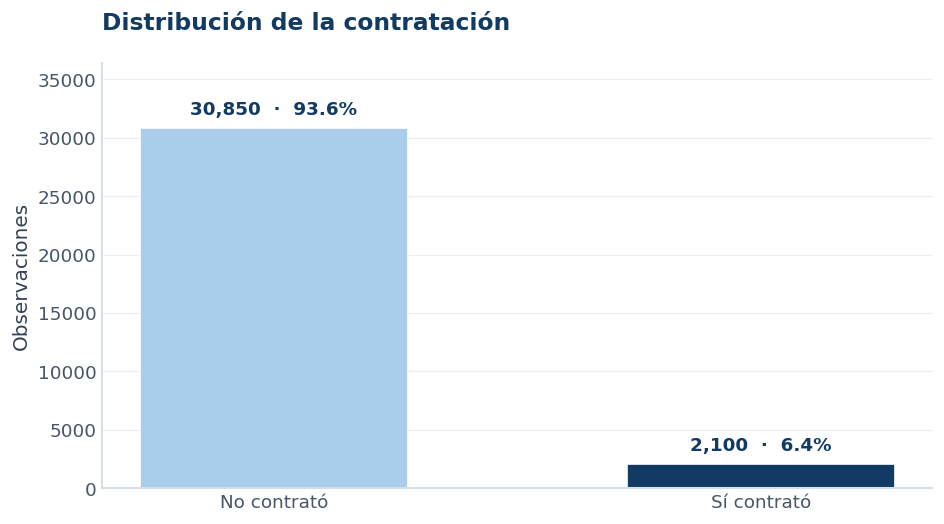

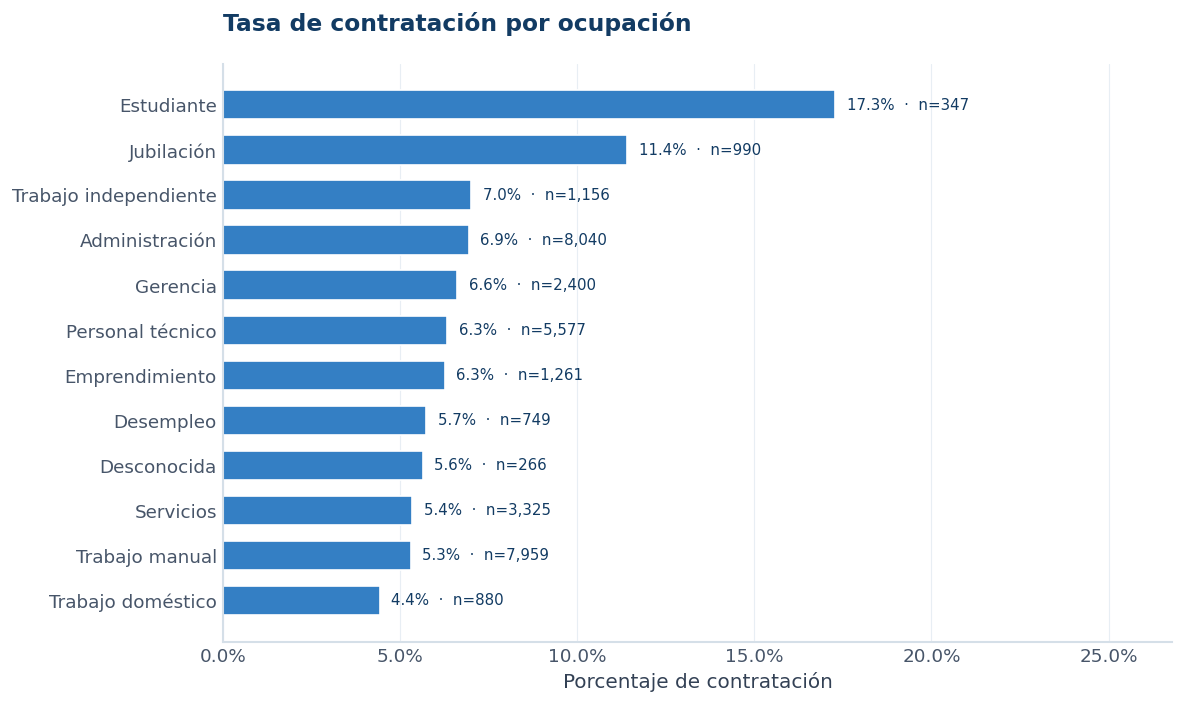

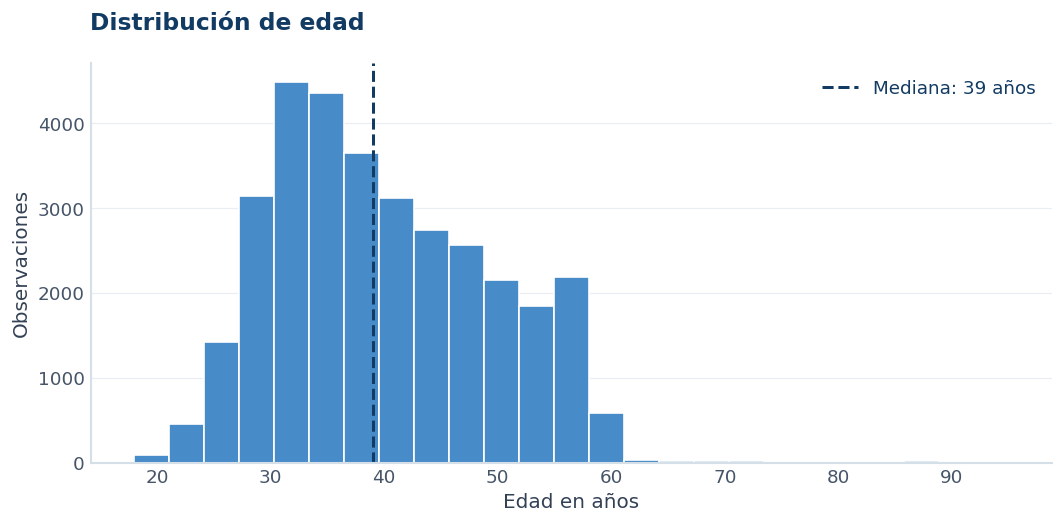

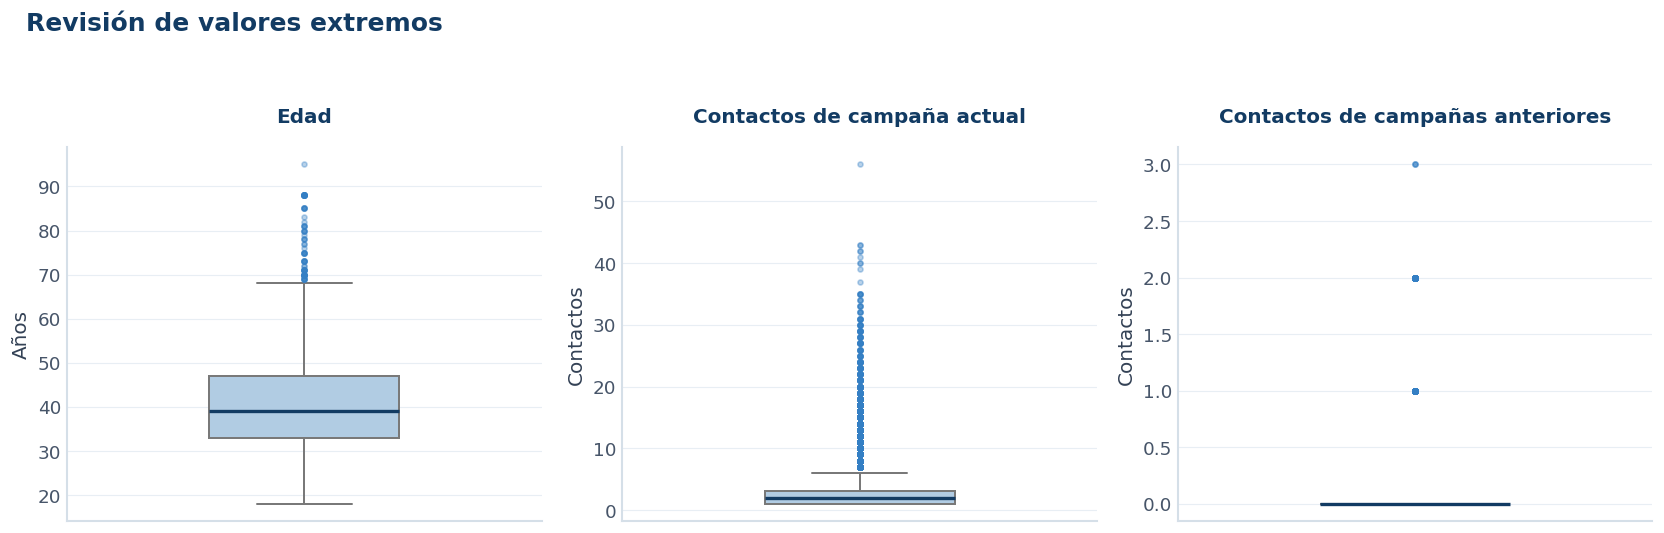

Los puntos fuera de los bigotes son candidatos a revisión; no se eliminan automáticamente.


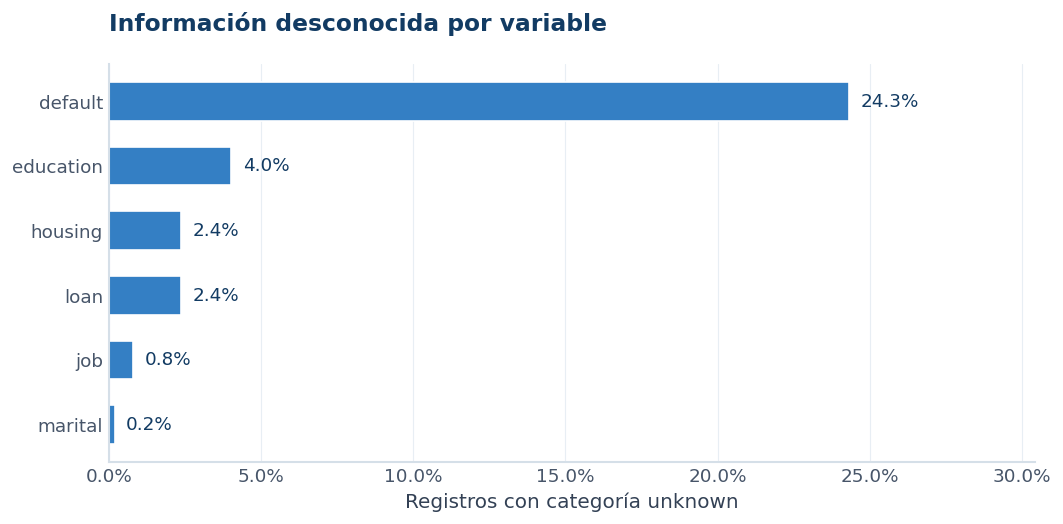

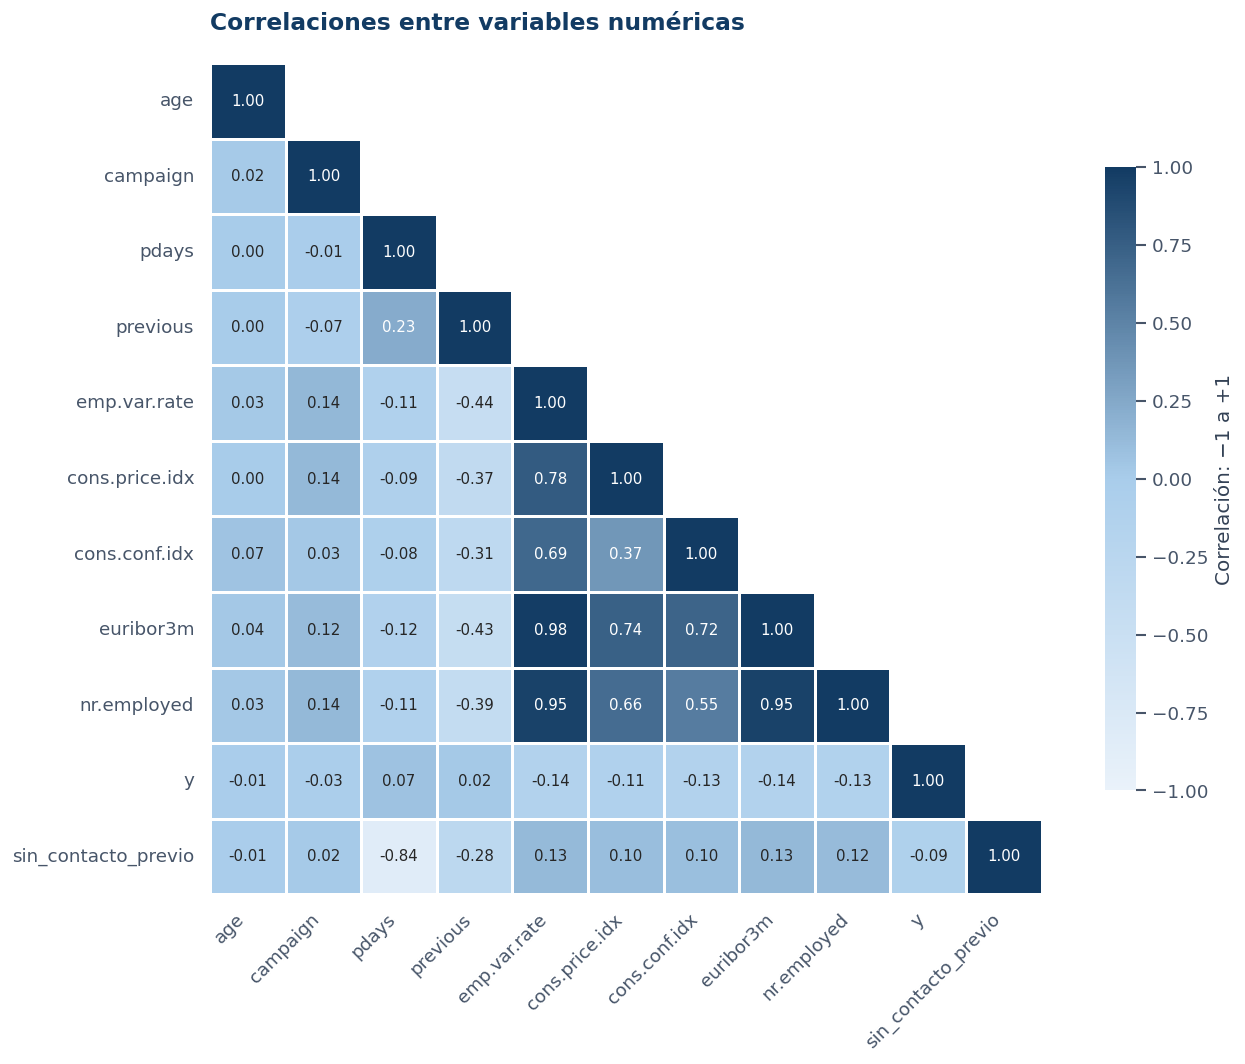

En la matriz, los tonos claros representan correlaciones negativas y los oscuros positivas. Los números indican su magnitud.


In [8]:
# CONFIGURACIÓN Y DATOS

AZUL_OSCURO = "#123B63"
AZUL_MEDIO = "#347FC4"
AZUL_CLARO = "#A9CDEB"
AZUL_SUAVE = "#EAF2FA"

sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#D5DFE8",
        "axes.labelcolor": "#334155",
        "text.color": AZUL_OSCURO,
        "xtick.color": "#475569",
        "ytick.color": "#475569",
        "font.size": 11,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "figure.dpi": 120
    }
)

# La prueba rápida usa una muestra y no sirve como resultado final.
if globals().get('MODO_PRUEBA_RAPIDA',False):
    df_limpio=df_limpio.sample(n=800,random_state=SEED).sort_index()
# Conservo el orden original y reservo el último 20% para prueba.
corte = int(len(df_limpio) * 0.80)

entrenamiento = df_limpio.iloc[:corte].copy()
prueba = df_limpio.iloc[corte:].copy()

X_train = entrenamiento.drop(columns="y")
y_train = entrenamiento["y"]

X_test = prueba.drop(columns="y")
y_test = prueba["y"]

assert set(entrenamiento["y"].unique()) == {0, 1}, (
    "La variable y debe estar codificada como 0 y 1."
)

print(f"Entrenamiento: {len(entrenamiento):,} registros")
print(f"Prueba reservada: {len(prueba):,} registros")


def estilo_limpio(ax, eje="y"):
    """Agrego una cuadrícula tenue sobre el eje indicado."""
    ax.set_axisbelow(True)
    ax.grid(axis=eje, color="#E8EEF4", linewidth=0.7)
    ax.tick_params(length=0)


# DISTRIBUCIÓN DE LA CONTRATACIÓN

conteos = (
    entrenamiento["y"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

porcentajes = conteos / conteos.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))

barras = ax.bar(
    ["No contrató", "Sí contrató"],
    conteos.values,
    color=[AZUL_CLARO, AZUL_OSCURO],
    width=0.55
)

for barra, porcentaje in zip(barras, porcentajes):
    ax.annotate(
        f"{int(barra.get_height()):,}  ·  {porcentaje:.1f}%",
        xy=(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height()
        ),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title("Distribución de la contratación", loc="left", pad=20)
ax.set_ylabel("Observaciones")
ax.set_ylim(0, conteos.max() * 1.18)

estilo_limpio(ax)
plt.tight_layout()
mostrar_y_guardar()


# CONTRATACIÓN POR OCUPACIÓN

etiquetas_ocupacion = {
    "admin.": "Administración",
    "blue-collar": "Trabajo manual",
    "entrepreneur": "Emprendimiento",
    "housemaid": "Trabajo doméstico",
    "management": "Gerencia",
    "retired": "Jubilación",
    "self-employed": "Trabajo independiente",
    "services": "Servicios",
    "student": "Estudiante",
    "technician": "Personal técnico",
    "unemployed": "Desempleo",
    "unknown": "Desconocida"
}

por_ocupacion = (
    entrenamiento.groupby("job")["y"]
    .agg(tasa="mean", registros="size")
    .sort_values("tasa")
)

etiquetas = [
    etiquetas_ocupacion.get(ocupacion, ocupacion)
    for ocupacion in por_ocupacion.index
]

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    etiquetas,
    por_ocupacion["tasa"],
    color=AZUL_MEDIO,
    height=0.65
)

for barra, (_, fila) in zip(barras, por_ocupacion.iterrows()):
    ax.annotate(
        f'{fila["tasa"]:.1%}  ·  n={int(fila["registros"]):,}',
        xy=(
            barra.get_width(),
            barra.get_y() + barra.get_height() / 2
        ),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Tasa de contratación por ocupación",
    loc="left",
    pad=20
)
ax.set_xlabel("Porcentaje de contratación")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, max(por_ocupacion["tasa"].max() * 1.55, 0.10))

estilo_limpio(ax, eje="x")
plt.tight_layout()
mostrar_y_guardar()



# DISTRIBUCIÓN DE EDAD

fig, ax = plt.subplots(figsize=(9, 4.5))

sns.histplot(
    data=entrenamiento,
    x="age",
    bins=25,
    color=AZUL_MEDIO,
    edgecolor="white",
    alpha=0.9,
    ax=ax
)

mediana_edad = entrenamiento["age"].median()

ax.axvline(
    mediana_edad,
    color=AZUL_OSCURO,
    linestyle="--",
    linewidth=1.8,
    label=f"Mediana: {mediana_edad:.0f} años"
)

ax.set_title("Distribución de edad", loc="left", pad=20)
ax.set_xlabel("Edad en años")
ax.set_ylabel("Observaciones")
ax.legend(frameon=False)

estilo_limpio(ax)
plt.tight_layout()
mostrar_y_guardar()



# VALORES EXTREMOS


fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

variables = [
    ("age", "Edad", "Años"),
    ("campaign", "Contactos de campaña actual", "Contactos"),
    ("previous", "Contactos de campañas anteriores", "Contactos")
]

for ax, (columna, titulo, etiqueta) in zip(axes, variables):
    sns.boxplot(
        data=entrenamiento,
        y=columna,
        color=AZUL_CLARO,
        width=0.4,
        linewidth=1.2,
        flierprops={
            "marker": "o",
            "markersize": 3,
            "markerfacecolor": AZUL_MEDIO,
            "markeredgecolor": AZUL_MEDIO,
            "alpha": 0.35
        },
        medianprops={
            "color": AZUL_OSCURO,
            "linewidth": 2
        },
        ax=ax
    )

    ax.set_title(titulo, fontsize=12, pad=15)
    ax.set_ylabel(etiqueta)
    ax.set_xlabel("")
    estilo_limpio(ax)

fig.suptitle(
    "Revisión de valores extremos",
    fontsize=15,
    fontweight="bold",
    x=0.02,
    ha="left"
)

plt.tight_layout(rect=[0, 0, 1, 0.92])
mostrar_y_guardar()

print(
    "Los puntos fuera de los bigotes son candidatos a revisión; "
    "no se eliminan automáticamente."
)


# INFORMACIÓN DESCONOCIDA

categoricas = entrenamiento.select_dtypes(
    include=["object", "string"]
).columns

desconocidos = (
    entrenamiento[categoricas]
    .eq("unknown")
    .mean()
    .sort_values()
)

desconocidos = desconocidos[desconocidos > 0]

if not desconocidos.empty:
    fig, ax = plt.subplots(figsize=(9, 4.5))

    barras = ax.barh(
        desconocidos.index,
        desconocidos.values,
        color=AZUL_MEDIO,
        height=0.6
    )

    for barra, porcentaje in zip(barras, desconocidos.values):
        ax.annotate(
            f"{porcentaje:.1%}",
            xy=(
                barra.get_width(),
                barra.get_y() + barra.get_height() / 2
            ),
            xytext=(7, 0),
            textcoords="offset points",
            va="center"
        )

    ax.set_title("Información desconocida por variable", loc="left", pad=20)
    ax.set_xlabel("Registros con categoría unknown")
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlim(0, desconocidos.max() * 1.25)

    estilo_limpio(ax, eje="x")
    plt.tight_layout()
    mostrar_y_guardar()
else:
    print("No se encontraron categorías unknown en entrenamiento.")



# CORRELACIONES NUMÉRICAS


correlaciones = (
    entrenamiento
    .select_dtypes(include="number")
    .corr()
)

mascara = np.triu(
    np.ones_like(correlaciones, dtype=bool),
    k=1
)

mapa_azules = LinearSegmentedColormap.from_list(
    "escala_azul",
    [AZUL_SUAVE, AZUL_CLARO, AZUL_OSCURO]
)

fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    correlaciones,
    mask=mascara,
    cmap=mapa_azules,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 9},
    linewidths=0.7,
    linecolor="white",
    square=True,
    cbar_kws={
        "label": "Correlación: −1 a +1",
        "shrink": 0.75
    },
    ax=ax
)

ax.set_title(
    "Correlaciones entre variables numéricas",
    loc="left",
    pad=20
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
mostrar_y_guardar()

print(
    "En la matriz, los tonos claros representan correlaciones negativas "
    "y los oscuros positivas. Los números indican su magnitud."
)
pd.DataFrame({'fila_original':df_limpio.index,'particion':
    ['entrenamiento']*corte+['prueba']*(len(df_limpio)-corte)}).to_csv(RESULTADOS/'particiones.csv',index=False)
assert y_train.nunique()==y_test.nunique()==2


## 6. Modelos

In [9]:
# Identifico los tipos de variables únicamente en entrenamiento.
columnas_numericas = X_train.select_dtypes(
    include="number"
).columns.tolist()

columnas_categoricas = X_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()


def crear_preprocesador(escalar=False):
    # Preparo las variables numéricas.
    pasos_numericos = [
        ("imputacion", SimpleImputer(strategy="median"))
    ]

    if escalar:
        pasos_numericos.append(
            ("escalado", StandardScaler())
        )

    # Preparo las variables categóricas.
    pasos_categoricos = [
        (
            "imputacion",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "codificacion",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]

    return ColumnTransformer([
        (
            "numericas",
            Pipeline(pasos_numericos),
            columnas_numericas
        ),
        (
            "categoricas",
            Pipeline(pasos_categoricos),
            columnas_categoricas
        )
    ])


# Modelo 1: regresión logística con escalado numérico.
modelo_logistico = Pipeline([
    ("preprocesamiento", crear_preprocesador(escalar=True)),
    (
        "modelo",
        LogisticRegression(
            max_iter=2000,
            random_state=110
        )
    )
])

# Modelo 2: Random Forest sin escalado numérico.
modelo_random_forest = Pipeline([
    ("preprocesamiento", crear_preprocesador(escalar=False)),
    (
        "modelo",
        RandomForestClassifier(
            n_estimators=100,
            random_state=110,
            n_jobs=1
        )
    )
])

# Conservo los modelos para el ajuste posterior.
modelos = {
    "Regresion_logistica": modelo_logistico,
    "Random_Forest": modelo_random_forest
}

for nombre, pipeline in modelos.items():
    print(f"\n{nombre}")
    display(pipeline)


Regresion_logistica


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('imputacion',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalado',
                                                                   StandardScaler())]),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed',
                                                   'sin_contacto_previo']),
                                                 ('categoricas',
                                                  Pipeline(steps=[('imputacion',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('codificacion',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('modelo',
                 LogisticRegression(max_iter=2000, random_state=110))])


Random_Forest


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('imputacion',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed',
                                                   'sin_contacto_previo']),
                                                 ('categoricas',
                                                  Pipeline(steps=[('imputacion',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('codificacion',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('modelo', RandomForestClassifier(n_jobs=1, random_state=110))])

## 7. Hiperparámetros y configuración de MLflow

In [10]:
# Defino las configuraciones que voy a comparar.
hiperparametros = {
    "Regresion_logistica": {
        "modelo__C": [0.1, 1.0, 10.0],
        "modelo__class_weight": [None, "balanced"]
    },

    "Random_Forest": {
        "modelo__n_estimators": [100, 200],
        "modelo__max_depth": [8, None],
        "modelo__min_samples_leaf": [2, 10],
        "modelo__class_weight": [None, "balanced"]
    }
}

# Creo los mismos cinco folds para ambos modelos.
validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(validacion.split(X_train, y_train))

# Registro varias métricas y selecciono por F1.
metricas_validacion = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


if globals().get('MODO_PRUEBA_RAPIDA',False):
    hiperparametros={
        'Regresion_logistica':{'modelo__C':[1.0]},
        'Random_Forest':{'modelo__n_estimators':[5],'modelo__max_depth':[3]}}
    folds=list(StratifiedKFold(n_splits=2,shuffle=True,random_state=SEED).split(X_train,y_train))

mlflow.set_tracking_uri('sqlite:///'+str(proyecto/'mlflow.db'))
cliente_mlflow=mlflow.tracking.MlflowClient()
nombre_experimento=('Actividad5_PRUEBA_RAPIDA' if globals().get('MODO_PRUEBA_RAPIDA',False)
                    else 'Actividad5_Marketing_Bancario')
experimento=cliente_mlflow.get_experiment_by_name(nombre_experimento)
id_experimento=(experimento.experiment_id if experimento else
    cliente_mlflow.create_experiment(nombre_experimento,artifact_location=(proyecto/'mlartifacts').as_uri()))
mlflow.set_experiment(experiment_id=id_experimento)

# Conservo versiones, datos y partición para trazabilidad.
paquetes=['numpy','pandas','scikit-learn','scipy','matplotlib','seaborn','mlflow','pyarrow','kagglehub','joblib','sqlalchemy']
versiones={p:importlib.metadata.version(p) for p in paquetes}
(RESULTADOS/'entorno.json').write_text(json.dumps({'python':sys.version,'paquetes':versiones},indent=2))
(proyecto/'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versiones.items())+'\n')


177

In [11]:
busquedas={}; mejores_modelos={}; resumen=[]; ids_ejecuciones={}
# El checkpoint evita repetir una búsqueda completada si ejecuto la celda otra vez.
# Solo cargo checkpoints creados por este proyecto; joblib no es seguro con archivos ajenos.
for nombre,pipeline in modelos.items():
    firma=hashlib.sha256(json.dumps({'sha':sha,'version_codigo':'1.1.0',
        'params':hiperparametros[nombre],'versiones':versiones,
        'n_train':len(X_train),'indice_train':X_train.index.tolist(),
        'folds':len(folds),'seed':SEED},sort_keys=True).encode()).hexdigest()
    checkpoint=proyecto/'modelos'/f'{nombre}_{firma[:12]}.joblib'
    with mlflow.start_run(run_name=nombre) as run:
        ids_ejecuciones[nombre]=run.info.run_id
        mlflow.set_tags({'version_codigo':'1.1.0','sha256_original':sha,
                        'modo':'prueba_rapida' if globals().get('MODO_PRUEBA_RAPIDA',False) else 'completo'})
        mlflow.log_params({'seed':SEED,'folds':len(folds),'umbral':0.5,'seleccion':'f1',
            'particion':'80_20_orden_original','n_train':len(X_train),'n_test':len(X_test),
            'duration_excluida':True})
        if checkpoint.exists():
            busqueda=joblib.load(checkpoint)
            mlflow.set_tag('origen_ajuste','checkpoint_compatible')
            print('Recuperado:',nombre)
        else:
            print('Ajustando:',nombre,flush=True)
            busqueda=GridSearchCV(pipeline,hiperparametros[nombre],scoring=metricas_validacion,
                refit='f1',cv=folds,n_jobs=2,verbose=1,error_score='raise')
            inicio=time.perf_counter()
            busqueda.fit(X_train,y_train)
            mlflow.log_metric('segundos_ajuste',time.perf_counter()-inicio)
            mlflow.set_tag('origen_ajuste','entrenamiento_nuevo')
            joblib.dump(busqueda,checkpoint)
        busquedas[nombre]=busqueda
        mejores_modelos[nombre]=busqueda.best_estimator_
        indice=busqueda.best_index_
        fila={'modelo':nombre,'mejores_parametros':busqueda.best_params_}
        for m in metricas_validacion:
            valor=float(busqueda.cv_results_[f'mean_test_{m}'][indice])
            fila[f'cv_{m}']=valor
            mlflow.log_metric(f'cv_{m}',valor)
        fila['cv_f1_std']=float(busqueda.cv_results_['std_test_f1'][indice])
        mlflow.log_metric('cv_f1_std',fila['cv_f1_std'])
        resumen.append(fila)
        mlflow.log_params({k:str(v) for k,v in busqueda.best_params_.items()})
        tabla_cv=pd.DataFrame(busqueda.cv_results_)
        ruta_cv=RESULTADOS/f'gridsearch_{nombre}.csv'
        tabla_cv.to_csv(ruta_cv,index=False)
        mlflow.log_artifact(str(ruta_cv),'validacion')
        # Cada configuración aparece como ejecución hija en el panel.
        for i,row in tabla_cv.iterrows():
            with mlflow.start_run(run_name=f'config_{i:02d}',nested=True):
                mlflow.log_params({k:str(v) for k,v in row['params'].items()})
                mlflow.log_metrics({f'cv_{m}':float(row[f'mean_test_{m}']) for m in metricas_validacion})
        ejemplo=X_train.head(5)
        mlflow.sklearn.log_model(busqueda.best_estimator_,artifact_path='modelo',
            signature=infer_signature(ejemplo,busqueda.predict(ejemplo)),input_example=ejemplo)
        mlflow.log_artifact(str(RESULTADOS/'manifest_datos.json'),'datos')
        mlflow.log_artifact(str(RESULTADOS/'entorno.json'),'entorno')
resumen_ajuste=pd.DataFrame(resumen).set_index('modelo').sort_values('cv_f1',ascending=False)
modelo_seleccionado=resumen_ajuste.index[0]
resumen_ajuste.to_csv(RESULTADOS/'metricas_validacion.csv')
display(resumen_ajuste.drop(columns='mejores_parametros').round(4))
print('Seleccionado únicamente por validación:',modelo_seleccionado)


Recuperado: Regresion_logistica


/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Recuperado: Random_Forest


/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_f1_std
modelo,,,,,,
Random_Forest,0.9236,0.3508,0.2314,0.2787,0.6604,0.0110
Regresion_logistica,0.7340,0.1187,0.4943,0.1914,0.6729,0.0095


Seleccionado únicamente por validación: Random_Forest


## 8. Métricas y comparación estadística

Evalúo únicamente después del ajuste, con umbral fijo 0.5. Reporto accuracy, precision, recall, F1 y ROC-AUC; MAE, RMSE y R² no aplican. La selección final permanece basada en validación aunque el orden cambie en prueba.

Uso bootstrap estratificado pareado de 1,000 remuestreos para el IC95% de la diferencia F1 (RF menos logística) y McNemar exacto para errores discordantes. No aplico una prueba t ingenua a folds solapados. Si el intervalo incluye cero, no demuestro diferencia ni equivalencia. La inferencia supone filas independientes y no incorpora la variabilidad de entrenamiento; sin ID de cliente y fechas completas, sus conclusiones son orientativas.

MÉTRICAS DE LOS MODELOS OPTIMIZADOS EN PRUEBA


,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Regresion_logistica,0.4892,0.3590,0.8362,0.5024,0.6940
Random_Forest,0.7109,0.6197,0.1610,0.2556,0.7181


La clase positiva es contratación (y=1). MAE, RMSE y R² no aplican porque es clasificación.


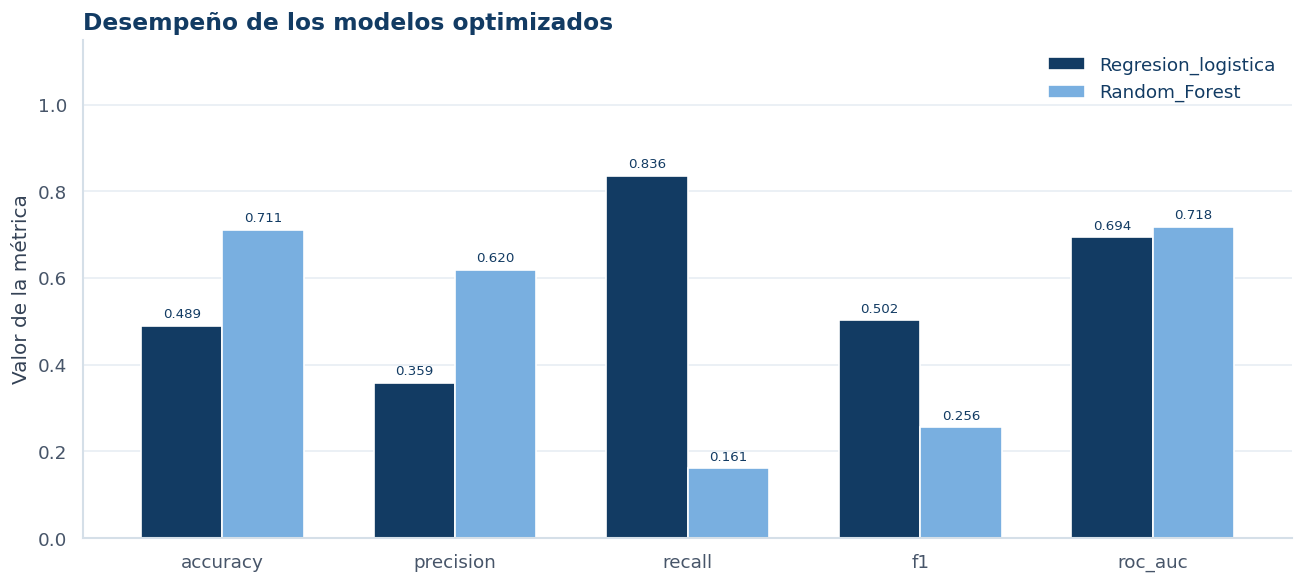


COMPARACIÓN ESTADÍSTICA


,resultado
Diferencia F1 (RF − logística),-2.467402e-01
IC 95%: límite inferior,-2.665454e-01
IC 95%: límite superior,-2.257193e-01
Solo logística acierta,1.719000e+03
Solo Random Forest acierta,3.545000e+03
McNemar: p-valor,1.636418e-142


F1: el intervalo favorece a regresión logística.
McNemar: detecto diferencias en las tasas de error al nivel de significancia de 0.05.


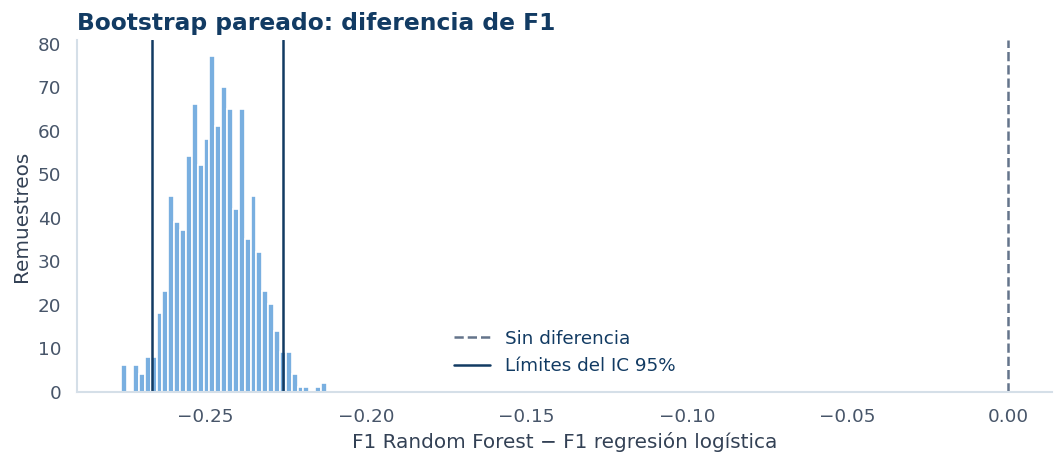

La inferencia supone filas independientes y no incorpora incertidumbre del entrenamiento.
McNemar compara errores, no F1. No reajusto el modelo usando prueba.


In [12]:

nombres = ["Regresion_logistica", "Random_Forest"]

if "mejores_modelos" not in globals():
    raise RuntimeError("Primero ejecuta el ajuste de hiperparámetros.")

for nombre in nombres:
    if nombre not in mejores_modelos:
        raise RuntimeError(f"Falta terminar el ajuste de {nombre}.")

predicciones = {}
filas_metricas = []

for nombre in nombres:
    modelo = mejores_modelos[nombre]

    # Obtengo la probabilidad de contratación.
    indice_positivo = list(modelo.classes_).index(1)
    probabilidades = modelo.predict_proba(X_test)[:, indice_positivo]

    # Mantengo el mismo umbral para ambos modelos.
    prediccion = (probabilidades >= 0.5).astype(int)
    predicciones[nombre] = prediccion

    filas_metricas.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, prediccion),
        "precision": precision_score(
            y_test, prediccion, zero_division=0
        ),
        "recall": recall_score(
            y_test, prediccion, zero_division=0
        ),
        "f1": f1_score(
            y_test, prediccion, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, probabilidades)
    })

tabla_metricas = (
    pd.DataFrame(filas_metricas)
    .set_index("modelo")
)

print("MÉTRICAS DE LOS MODELOS OPTIMIZADOS EN PRUEBA")
display(tabla_metricas.round(4))

print(
    "La clase positiva es contratación (y=1). "
    "MAE, RMSE y R² no aplican porque es clasificación."
)

# Gráfica comparativa en tonos azules.
fig, ax = plt.subplots(figsize=(11, 5))

tabla_metricas.T.plot.bar(
    ax=ax,
    color=["#123B63", "#79AFE0"],
    rot=0,
    width=0.7
)

ax.set_title("Desempeño de los modelos optimizados", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0, 1.15)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E8EEF4")
ax.set_axisbelow(True)
ax.legend(frameon=False)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", padding=3, fontsize=8)

plt.tight_layout()
mostrar_y_guardar()

# COMPARACIÓN ESTADÍSTICA DE RESULTADOS

y_real = np.asarray(y_test)
pred_lr = predicciones["Regresion_logistica"]
pred_rf = predicciones["Random_Forest"]

# Bootstrap estratificado pareado:
# remuestreo las mismas observaciones para ambos modelos,
# conservando el número de casos de cada clase.
rng = np.random.default_rng(42)

grupos = [
    np.flatnonzero(y_real == clase)
    for clase in [0, 1]
]

diferencias = []

for _ in range(1000):
    indices = np.concatenate([
        rng.choice(grupo, size=len(grupo), replace=True)
        for grupo in grupos
    ])

    diferencias.append(
        f1_score(
            y_real[indices], pred_rf[indices], zero_division=0
        )
        - f1_score(
            y_real[indices], pred_lr[indices], zero_division=0
        )
    )

limite_inferior, limite_superior = np.quantile(
    diferencias, [0.025, 0.975]
)

diferencia_f1 = (
    tabla_metricas.loc["Random_Forest", "f1"]
    - tabla_metricas.loc["Regresion_logistica", "f1"]
)

# McNemar exacto: comparo los errores discordantes.
solo_lr_acierta = int(
    ((pred_lr == y_real) & (pred_rf != y_real)).sum()
)

solo_rf_acierta = int(
    ((pred_lr != y_real) & (pred_rf == y_real)).sum()
)

discordantes = solo_lr_acierta + solo_rf_acierta

p_valor = (
    binomtest(
        solo_lr_acierta,
        n=discordantes,
        p=0.5,
        alternative="two-sided"
    ).pvalue
    if discordantes > 0
    else 1.0
)

comparacion_estadistica = pd.DataFrame({
    "resultado": {
        "Diferencia F1 (RF − logística)": diferencia_f1,
        "IC 95%: límite inferior": limite_inferior,
        "IC 95%: límite superior": limite_superior,
        "Solo logística acierta": solo_lr_acierta,
        "Solo Random Forest acierta": solo_rf_acierta,
        "McNemar: p-valor": p_valor
    }
})

print("\nCOMPARACIÓN ESTADÍSTICA")
display(comparacion_estadistica)

if limite_inferior > 0:
    print("F1: el intervalo favorece a Random Forest.")
elif limite_superior < 0:
    print("F1: el intervalo favorece a regresión logística.")
else:
    print(
        "F1: el intervalo incluye cero; no encuentro evidencia "
        "concluyente de una diferencia. Esto no demuestra equivalencia."
    )

if p_valor < 0.05:
    print(
        "McNemar: detecto diferencias en las tasas de error "
        "al nivel de significancia de 0.05."
    )
else:
    print(
        "McNemar: no detecto diferencias en las tasas de error "
        "al nivel de significancia de 0.05."
    )

# Visualizo la incertidumbre de la diferencia de F1.
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(
    diferencias,
    bins=35,
    color="#79AFE0",
    edgecolor="white"
)

ax.axvline(
    0, color="#64748B", linestyle="--", label="Sin diferencia"
)
ax.axvline(
    limite_inferior, color="#123B63", label="Límites del IC 95%"
)
ax.axvline(limite_superior, color="#123B63")

ax.set_title("Bootstrap pareado: diferencia de F1", loc="left")
ax.set_xlabel("F1 Random Forest − F1 regresión logística")
ax.set_ylabel("Remuestreos")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
mostrar_y_guardar()
tabla_metricas.to_csv(RESULTADOS/'metricas_prueba.csv')
comparacion_estadistica.to_csv(RESULTADOS/'comparacion_estadistica.csv')
print('La inferencia supone filas independientes y no incorpora incertidumbre del entrenamiento.')
print('McNemar compara errores, no F1. No reajusto el modelo usando prueba.')


## 9. Verificación de MLflow

Completo los runs con métricas finales, código, tablas y gráficas. Compruebo además que el modelo guardado pueda recuperarse y produzca las mismas predicciones. La tabla de verificación es evidencia real del almacén; las capturas del panel se recopilan en la sección siguiente.

In [13]:
# Completo las ejecuciones principales con métricas de prueba y artefactos.
for nombre in nombres:
    with mlflow.start_run(run_id=ids_ejecuciones[nombre]):
        mlflow.log_metrics({'test_'+m:float(tabla_metricas.loc[nombre,m]) for m in tabla_metricas.columns})
        mlflow.set_tag('seleccionado_por_validacion',str(nombre==modelo_seleccionado))
        mlflow.log_artifacts(str(GRAFICAS),'graficas')
        for p in ['metricas_prueba.csv','comparacion_estadistica.csv','metricas_validacion.csv','diccionario_datos.csv']:
            mlflow.log_artifact(str(RESULTADOS/p),'resultados')
        mlflow.log_artifacts(str(proyecto/'fuentes'),'codigo')
# Verifico parámetros, métricas, artefactos y carga del modelo registrado.
filas=[]
for nombre,rid in ids_ejecuciones.items():
    r=cliente_mlflow.get_run(rid)
    assert r.info.status=='FINISHED' and r.data.params and 'test_f1' in r.data.metrics
    assert cliente_mlflow.list_artifacts(rid,'modelo')
    recuperado=mlflow.sklearn.load_model(f'runs:/{rid}/modelo')
    np.testing.assert_array_equal(recuperado.predict(X_test.head(5)),mejores_modelos[nombre].predict(X_test.head(5)))
    filas.append({'modelo':nombre,'run_id':rid,'estado':r.info.status,**r.data.metrics})
evidencia=pd.DataFrame(filas)
display(evidencia)
evidencia.to_csv(proyecto/'evidencias/mlflow/ejecuciones_verificadas.csv',index=False)
cliente_mlflow.search_runs([id_experimento])
(RESULTADOS/'run_ids.json').write_text(json.dumps(ids_ejecuciones,indent=2))
print('MLflow verificado: parámetros, métricas, artefactos y predicción del modelo recuperado.')


,modelo,run_id,estado,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_f1_std,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,Regresion_logistica,b7f34088269b40eab0591254079bab9e,FINISHED,0.733991,0.118714,0.494286,0.191422,0.672896,0.009468,0.489196,0.359026,0.836220,0.502365,0.69405
1,Random_Forest,e457da123e3c468ea199f4d0d06cc915,FINISHED,0.923612,0.350785,0.231429,0.278713,0.660389,0.011002,0.710852,0.619697,0.161024,0.255625,0.71814


MLflow verificado: parámetros, métricas, artefactos y predicción del modelo recuperado.


## 10. Panel y capturas de MLflow

Ejecuto esta celda después del entrenamiento. Abro el enlace del panel y selecciono el experimento `Actividad5_Marketing_Bancario`. Tomo capturas de: (1) ejecuciones y métricas, (2) comparación de los dos modelos y (3) parámetros/artefactos. Luego uso la celda de subida para conservar las capturas en el proyecto. No se generan capturas simuladas.

La celda es opcional para `Ejecutar todas`: cambio `ABRIR_PANEL` a True cuando voy a tomar las capturas.

In [14]:
ABRIR_PANEL=False
if ABRIR_PANEL:
    import subprocess, socket, time
    from google.colab import output
    if 'proceso_mlflow' not in globals() or proceso_mlflow.poll() is not None:
        log_panel=open(proyecto/'mlflow_ui.log','w')
        proceso_mlflow=subprocess.Popen([sys.executable,'-m','mlflow','ui',
            '--backend-store-uri',mlflow.get_tracking_uri(),'--host','0.0.0.0','--port','5000'],
            stdout=log_panel,stderr=subprocess.STDOUT)
    listo=False
    for _ in range(30):
        with socket.socket() as conexion:
            if conexion.connect_ex(('127.0.0.1',5000))==0:
                listo=True;break
        time.sleep(1)
    if not listo: raise RuntimeError('El panel no inició. Revisar /content/Actividad5/mlflow_ui.log')
    output.serve_kernel_port_as_window(5000)


In [15]:
SUBIR_CAPTURAS=False
if SUBIR_CAPTURAS:
    from google.colab import files
    for nombre,contenido in files.upload().items():
        if Path(nombre).suffix.lower() in ['.png','.jpg','.jpeg']:
            (proyecto/'evidencias/mlflow'/Path(nombre).name).write_bytes(contenido)
print('Capturas:',[p.name for p in (proyecto/'evidencias/mlflow').glob('*') if p.suffix.lower() in ['.png','.jpg','.jpeg']])


Capturas: []


## 11. Reflexión sobre deuda técnica y MLOps

La principal deuda técnica es la antigüedad de los datos, la ausencia de identificadores y fechas completas, y la validación interna que mezcla periodos. Antes de implementar incorporaría validación temporal, revisión de variables disponibles y control de contactos repetidos.

Evaluaría calibración y umbrales con costos comerciales en validación, sin reutilizar prueba. Revisaría diferencias entre grupos para evitar exclusiones injustificadas. Los resultados son predictivos y no prueban el efecto causal de llamar.

Los pipelines y MLflow mejoran la trazabilidad, pero todavía necesito pruebas de calidad, almacenamiento persistente, monitoreo de drift y desempeño, revisión humana y criterios de reentrenamiento/reversión. Colab y SQLite son adecuados para esta actividad, no constituyen un servicio de producción.

## 12. README y CHANGELOG


In [16]:
from datetime import datetime
from zoneinfo import ZoneInfo
fecha=datetime.now(ZoneInfo('America/Mexico_City')).date().isoformat()
readme=f"""# Actividad5 — Marketing bancario
Repositorio: https://github.com/BrendaNallely/Actividad5

Predigo contratación de depósitos mediante regresión logística y Random Forest.

## Datos y atribución
Kaggle: https://www.kaggle.com/datasets/sahistapatel96/bankadditionalfullcsv
Fuente original: https://doi.org/10.24432/C5K306 (Moro, Rita y Cortez, 2014).
Licencia original UCI: CC BY 4.0. Datos históricos de campañas de un banco portugués.
Versión bank-additional-full: 41,188 filas y 21 columnas originales.
SHA256: {sha}. Fuente efectiva registrada en resultados/manifest_datos.json.

## Estructura
- datos/datos_ini/: CSV original sin modificar.
- datos/datos_limp/: datos limpios antes de imputación/escalado.
- fuentes/entrena.ipynb: cuaderno Colab.
- fuentes/datos_prep.py: función de limpieza.
- fuentes/train.py: entrenamiento, evaluación y registro MLflow.
- resultados/: diccionario, particiones, búsquedas, métricas y versiones.
- evidencias/: PNG comparativos, capturas reales y verificación MLflow.
- mlflow.db, mlartifacts/, modelos/: incluidos en respaldo ZIP; excluidos de Git.

## Reproducción
1. Abrir fuentes/entrena.ipynb en una sesión nueva de Colab con CPU.
2. Ejecutar en orden. Si cambia un paquete ya cargado, reiniciar una vez.
3. El ajuste completo realiza 110 fits de validación y dos reajustes.
4. Activar ABRIR_PANEL para capturas; después SUBIR_CAPTURAS.
5. Guardar el cuaderno ejecutado y generar el ZIP antes de cerrar Colab.

Alternativa local (Python 3.11–3.13):
    pip install -r requirements.txt
    python fuentes/train.py --root .
Prueba rápida funcional: añadir --smoke y usar un --root separado; no entregar sus métricas.
El script descarga Kaggle si falta el original y usa UCI como respaldo.

## Decisiones
Excluyo duration, conservo unknown y filas idénticas sin ID.
Recodifico pdays=999 junto con una bandera de ausencia de contacto.
Imputación y One-Hot dentro de cada fold; escalado solo en logística.
Prueba: último 20% por orden original. Cinco folds estratificados dentro del 80% inicial.
La validación interna mezcla periodos; no equivale a una evaluación temporal de producción.
Selección: F1 de validación, umbral 0.5. No reajusto según prueba.
Bootstrap pareado de F1 y McNemar de errores; suponen independencia entre filas.

## Resultado de esta ejecución
Seleccionado por validación: {modelo_seleccionado}.
{tabla_metricas.to_markdown() if importlib.util.find_spec('tabulate') else tabla_metricas.to_string()}

## MLflow y restauración
El notebook verifica parámetros, métricas, artefactos y recarga de modelos.
Para restaurar el ZIP de Colab, conservar /content/Actividad5: los URI de artefactos son absolutos.
Desde un script local, mantener la misma ruta usada al entrenar, o regenerar el almacén.
    mlflow ui --backend-store-uri sqlite:////content/Actividad5/mlflow.db --port 5000
Las gráficas y tablas de Git permiten revisar resultados sin el almacén completo.

## Limitaciones y entrega
Datos antiguos, sin ID ni fecha exacta; no prueban causalidad ni desempeño en México actual.
El reporte PDF/Word se prepara por separado. Las capturas deben ser reales.
No se incluyen tokens, contraseñas ni archivos de autenticación en Git.
"""
(proyecto/'README.md').write_text(readme,encoding='utf-8')
changelog=f"""# CHANGELOG
## 1.1.0 — {fecha}
- Integré estructura requerida, scripts autónomos y exportación del notebook.
- Corregí instalación de MLflow/PyArrow y registré versiones efectivas.
- Conservé originales, unknown y filas idénticas; excluí duration.
- Añadí SHA256, diccionario, particiones, PNG y checkpoints de búsqueda.
- Ajusté 6 configuraciones logísticas y 16 de Random Forest con cinco folds.
- Registré combinaciones, modelos y métricas en MLflow y verifiqué su recuperación.
- Comparé F1 con bootstrap pareado y errores con McNemar.
- Preparé Git, remoto GitHub y publicación opcional autenticada sin force push.
- Seleccionado por validación en esta ejecución: {modelo_seleccionado}.
- Reporte PDF/Word: fuera del alcance de esta modificación del cuaderno.

## 0.1.0
- Base inicial: descarga, limpieza, gráficas azules y comparación de modelos.
"""
(proyecto/'CHANGELOG.md').write_text(changelog,encoding='utf-8')
(proyecto/'.gitignore').write_text(
    '.ipynb_checkpoints/\n__pycache__/\n*.pyc\n.env\n*.joblib\nmodelos/\nmlartifacts/\nmlruns/\nmlflow.db*\n*.log\n',encoding='utf-8')
print('README, CHANGELOG y .gitignore actualizados.')


README, CHANGELOG y .gitignore actualizados.


## 13. Conservar el notebook en fuentes/entrena.ipynb

In [ ]:
import nbformat
try:
    from google.colab import _message
    respuesta=_message.blocking_request('get_ipynb',timeout_sec=30)
    cuaderno=respuesta.get('ipynb')
    if cuaderno is None: raise RuntimeError('Colab no devolvió el notebook')
    if isinstance(cuaderno,str): cuaderno=json.loads(cuaderno)
    nbformat.validate(nbformat.from_dict(cuaderno))
    (proyecto/'fuentes/entrena.ipynb').write_text(json.dumps(cuaderno,ensure_ascii=False,indent=1),encoding='utf-8')
    print('Notebook actual guardado con sus salidas disponibles.')
except Exception as error:
    print('No se pudo recuperar el notebook automáticamente. Activa SUBIR_NOTEBOOK y sube el .ipynb descargado:',type(error).__name__)
SUBIR_NOTEBOOK=False
if SUBIR_NOTEBOOK:
    from google.colab import files
    subidos=files.upload()
    for nombre,contenido in subidos.items():
        if nombre.endswith('.ipynb'):
            candidato=nbformat.reads(contenido.decode('utf-8'),as_version=4)
            nbformat.validate(candidato)
            (proyecto/'fuentes/entrena.ipynb').write_bytes(contenido)
            print('Copia ejecutada incorporada.')


## 14. Inicializar Git y conectar GitHub

In [ ]:
import subprocess
URL_REPOSITORIO='https://github.com/BrendaNallely/Actividad5.git'
NOMBRE_AUTOR='Brenda Nallely'
CORREO_AUTOR=''  # Escribir correo Git de autor; puede ser el noreply de GitHub.

def git(*args,check=True):
    return subprocess.run(['git','-C',str(proyecto),*args],check=check,text=True,capture_output=True)

if not (proyecto/'.git').exists():
    git('init','-b','main')
remoto=git('remote','get-url','origin',check=False)
if remoto.returncode!=0:
    git('remote','add','origin',URL_REPOSITORIO)
elif remoto.stdout.strip()!=URL_REPOSITORIO:
    raise RuntimeError('El remoto existente es distinto. Revisar antes de continuar.')
print('Git inicializado. Remoto:',git('remote','get-url','origin').stdout.strip())
if CORREO_AUTOR:
    git('config','user.name',NOMBRE_AUTOR)
    git('config','user.email',CORREO_AUTOR)
    git('add','datos','fuentes','README.md','CHANGELOG.md','requirements.txt','.gitignore','resultados','evidencias')
    if git('diff','--cached','--quiet',check=False).returncode==1:
        print(git('commit','-m','Actividad5: modelos optimizados, evaluación y MLflow').stdout)
    else:
        print('Sin cambios nuevos para commit.')
else:
    print('Completar CORREO_AUTOR y volver a ejecutar para crear el commit.')


 Validar estructura y descargar ZIP


In [ ]:
import zipfile, sqlite3
requeridos=['datos/datos_ini/bank-additional-full.csv','datos/datos_limp/bank_limpio.csv',
    'fuentes/entrena.ipynb','fuentes/datos_prep.py','fuentes/train.py',
    'README.md','CHANGELOG.md','requirements.txt','mlflow.db',
    'evidencias/mlflow/ejecuciones_verificadas.csv']
faltantes=[p for p in requeridos if not (proyecto/p).exists()]
if faltantes: raise FileNotFoundError('Faltan archivos: '+', '.join(faltantes))
capturas=[p for p in (proyecto/'evidencias/mlflow').iterdir() if p.suffix.lower() in ['.png','.jpg','.jpeg']]
print('Capturas reales incorporadas:',len(capturas))
if not capturas: print('PENDIENTE: subir capturas del panel y volver a generar el ZIP.')
print('Reporte PDF/Word: se prepara y añade por separado.')
with sqlite3.connect(proyecto/'mlflow.db') as con:
    con.execute('PRAGMA wal_checkpoint(FULL)')
ruta_zip=proyecto.parent/'Actividad5.zip'
with zipfile.ZipFile(ruta_zip,'w',zipfile.ZIP_DEFLATED) as z:
    for p in proyecto.rglob('*'):
        rel=p.relative_to(proyecto)
        if not p.is_file() or any(x in ['.git','__pycache__','.ipynb_checkpoints'] for x in rel.parts):continue
        if p.suffix=='.log':continue
        z.write(p,Path('Actividad5')/rel)
print('Estructura verificada. ZIP:',ruta_zip)
from google.colab import files
files.download(str(ruta_zip))


In [ ]:
from google.colab import drive
drive.mount('/content/drive')